In [23]:

import os, sys, math, glob, json, random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report
from scipy.signal import welch, butter, filtfilt
from scipy.stats import kurtosis
import mne

# GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    try:
        print("GPU:", torch.cuda.get_device_name(0))
    except:
        pass


Device: cuda
GPU: NVIDIA GeForce GTX 1650 Ti


In [24]:
# Global plotting style
import seaborn as sns
sns.set(context='notebook', style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})


##Cell 2: Checking GPU Availability and Importing the dataset
1) Creates a Subjects Range from 1 to 66 patients  
2) sampling rate in dataset = 500 readings every second
3) 5-second windows --> cuts EEG data into 5-second pieces
4) 50% overlap --> 50% overlap between EEG segments
5) number of Channels = 19

In [25]:
##Cell 2
datasetPath = r"/media/shashank/307ADF5A7ADF1C02/EEG_Project/EEG"  
subjects = [f"sub-{i:03d}" for i in range(1,66)]  
fs_target = 500  # sampling rate in dataset (already 500)
seg_sec = 5      # 5-second windows
overlap = 0.5    # 50% overlap
window_samples = int(seg_sec * fs_target)
step_samples = int(window_samples * (1 - overlap))
n_channels_expected = 19
save_dir = Path("results_bilstm")
save_dir.mkdir(exist_ok=True)


In [26]:
# Cell 3: ueses wavelet-packet proxy

In [27]:
# Cell 3
use_tqwt = False
try:
    import tqwt  # preferred package if available
    use_tqwt = True
    print("tqwt package available.")
except Exception as e:
    print("tqwt not found. Will use fallback (wavelet-packet approx) if necessary.")
    use_tqwt = False

# Fallback: we'll use pywt WaveletPacket as approximate multi-band split when tqwt unavailable
try:
    import pywt
    has_pywt = True
except:
    has_pywt = False
    raise ImportError("pywt not installed. Please install pywt (pip install PyWavelets).")


tqwt not found. Will use fallback (wavelet-packet approx) if necessary.


Cell 4: 
This cell extracts useful information (features) from raw 
EEG signals so that the Bi-LSTM model can understand them better.
Entropy --> quantify the impurity, disorder, or uncertainty within a dataset.
1) shannon_entropy --> How random or unpredictable the EEG signal is
2) tsallis_entropy --> Finding rare spikes in EEG that normal measures might miss
3) renyi_entropy --> Measures how concentrated the EEG signal is
4) katz_fd --> Signal complexity,How rough or jagged the EEG signal is
5) kurtosis_feature --> Peakedness of the EEG signal

In [28]:
# Cell 4: feature functions
def shannon_entropy(x, bins=100):
    p, _ = np.histogram(x, bins=bins, density=True)
    p = p[p>0]
    return -np.sum(p * np.log2(p))

def tsallis_entropy(x, q=2.0, bins=100):
    p,_ = np.histogram(x, bins=bins, density=True)
    p = p[p>0]
    if q == 1.0:
        return -np.sum(p * np.log(p))
    return (1.0 - np.sum(p**q)) / (q - 1.0)

def renyi_entropy(x, q=0.5, bins=100):
    p,_ = np.histogram(x, bins=bins, density=True)
    p = p[p>0]
    return (1.0/(1.0 - q)) * np.log(np.sum(p**q))

def katz_fd(x):
    x = np.asarray(x)
    n = len(x)
    if n < 2:
        return 0.0
    L = np.sum(np.sqrt(1 + np.diff(x)**2))
    d = np.max(np.sqrt((np.arange(n) - 0)**2 + (x - x[0])**2))
    if L == 0 or d == 0:
        return 0.0
    return np.log10(n) / (np.log10(n) + np.log10(d / L))

def kurtosis_feature(x):
    return float(kurtosis(x, fisher=False, nan_policy='omit'))

# wrapper to compute 4 features from a 1D subband
def features_from_subband(x):
    x = np.asarray(x)
    if x.std() == 0:
        x = x - x.mean()
    return [katz_fd(x), tsallis_entropy(x, q=2.0), renyi_entropy(x, q=0.5), kurtosis_feature(x)]


In [29]:
# Cell 5: estimate Q,R,J from signal power (simple heuristic)
def estimate_tqwt_params(signal, fs):
    # PSD to find dominant freq f0 and approximate bandwidth
    f, Pxx = welch(signal, fs=fs, nperseg=min(len(signal), 2048))## Welches Methods 
    f0 = f[np.argmax(Pxx)]                                       ##Finds frequency with maximum power(This is the strongest brain rhythm)
    # half-power bandwidth approx
    peak = np.max(Pxx)
    inds = np.where(Pxx >= peak/2)[0]
    if len(inds) > 1:
        bw = f[inds[-1]] - f[inds[0]]
    else:
        bw = max(1.0, f0*0.5)
    Q = max(0.5, float(f0) / max(bw, 1e-6))
    # redundancy heuristic: bound between 2 and 12
    R = int(np.clip(fs / (2 * max(f0,1.0)), 2, 12))
    # J selection: want ~2 Hz subband width: J ~ log2((fs/2)/target_bw)
    target_bw = 2.0
    J = int(np.clip(np.floor(np.log2((fs/2)/target_bw)), 3, 8))
    return float(Q), int(R), int(J)

# quick test (won't run until dataset provided)
# print(estimate_tqwt_params(np.random.randn(1000), fs_target))


In [30]:
# Cell 6: decomposition function returning list of subband time-series (length J+1)
def decompose_tqwt(signal, Q, R, J, fs):
    # Try tqwt library if available
    if use_tqwt:
        try:
            # tqwt API vary. Example: tqwt.tqwt(signal, Q, r, J) -> coeffs or subbands
            coeffs = tqwt.tqwt(signal, Q, R, J)  # may require adaptation
            # user must adapt if API differs. We'll expect reconstructed subbands returned.
            return coeffs
        except Exception as e:
            pass
    # Fallback: use wavelet packet decomposition to produce J+1 components
    wp = pywt.WaveletPacket(data=signal, wavelet='db4', mode='symmetric', maxlevel=J)
    # Collect nodes at level J (details approximating bands)
    nodes = [node.path for node in wp.get_level(J, order='freq')]
    subbands = []
    for path in nodes:
        node_data = wp[path].data
        # Reconstruct node to full length via inverse transform on that node only
        # Simpler: upsample node_data to original length by interpolation
        up = np.interp(np.linspace(0, len(node_data)-1, len(signal)), np.arange(len(node_data)), node_data)
        subbands.append(up)
    # ensure we return exactly J+1 bands; if fewer, pad with zeros
    if len(subbands) < J+1:
        for _ in range(J+1 - len(subbands)):
            subbands.append(np.zeros_like(signal))
    return subbands[:J+1]


In [31]:
import pandas as pd
from pathlib import Path

data_root = Path(datasetPath)
label_file = Path(r"/media/shashank/307ADF5A7ADF1C02/EEG_Project/labels.xlsx")

# read Excel file
labels_df = pd.read_excel(label_file)

# clean column names
labels_df.columns = labels_df.columns.str.strip().str.lower()

# Normalize label text and build dictionary
labels = {}
for _, row in labels_df.iterrows():
    sid = str(row['subject']).strip()
    lab = str(row['label']).strip().lower()

    if 'a' in lab or 'alzheimer' in lab:
        labels[sid] = 1
    elif 'control' in lab or 'c' in lab or 'healthy' in lab:
        labels[sid] = 0
    elif lab in ['1', '0']:
        labels[sid] = int(lab)
    else:
        labels[sid] = None


# --- Build manifest: subject, EEG file path, label ---
manif = []

for sub in subjects:
    subdir = data_root / sub
    if not subdir.exists():
        subdir = next(data_root.glob(f"**/{sub}"), None)
        if subdir is None:
            print("Missing:", sub)
            continue

    eeg_files = list(subdir.glob("**/*.set")) + \
                list(subdir.glob("**/*.edf")) + \
                list(subdir.glob("**/*.bdf"))

    if not eeg_files:
        print("No EEG file for", sub)
        continue

    filepath = eeg_files[0]
    label = labels.get(sub, None)

    if label is None:
        print("Label missing for", sub, "- skipping.")
        continue

    manif.append((sub, str(filepath), int(label)))

print("Subjects collected:", len(manif))
print("Example:", manif[:3])



Subjects collected: 65
Example: [('sub-001', '/media/shashank/307ADF5A7ADF1C02/EEG_Project/EEG/eeg/sub-001/eeg/sub-001_task-eyesclosed_eeg.set', 1), ('sub-002', '/media/shashank/307ADF5A7ADF1C02/EEG_Project/EEG/eeg/sub-002/eeg/sub-002_task-eyesclosed_eeg.set', 1), ('sub-003', '/media/shashank/307ADF5A7ADF1C02/EEG_Project/EEG/eeg/sub-003/eeg/sub-003_task-eyesclosed_eeg.set', 1)]


/tmp/ipykernel_7052/3569509094.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df_manif, palette='viridis')


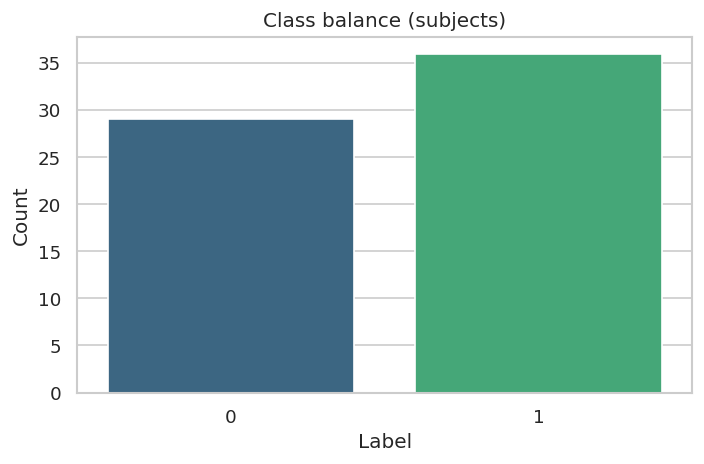

   subject                                           filepath  label
0  sub-001  /media/shashank/307ADF5A7ADF1C02/EEG_Project/E...      1
1  sub-002  /media/shashank/307ADF5A7ADF1C02/EEG_Project/E...      1
2  sub-003  /media/shashank/307ADF5A7ADF1C02/EEG_Project/E...      1
3  sub-004  /media/shashank/307ADF5A7ADF1C02/EEG_Project/E...      1
4  sub-005  /media/shashank/307ADF5A7ADF1C02/EEG_Project/E...      1


In [32]:
# Diagnostic: class balance of subjects (manifest)
import pandas as _pd
df_manif = _pd.DataFrame(manif, columns=['subject','filepath','label'])
plt.figure(figsize=(6,4))
sns.countplot(x='label', data=df_manif, palette='viridis')
plt.xlabel('Label'); plt.ylabel('Count'); plt.title('Class balance (subjects)')
plt.tight_layout()
plt.savefig(save_dir / 'class_balance_subjects.png', dpi=150)
plt.show()

# show first few manifest entries for quick inspection
print(df_manif.head())


In [33]:
# Cell 8: segmentation and live TQWT feature extraction (fixed)

def bandpass(x, lo=0.5, hi=45, fs=fs_target, order=4):
    b, a = butter(order, [lo/(fs/2), hi/(fs/2)], btype='band')
    return filtfilt(b, a, x)

all_features = []
all_labels = []
all_subject_idx = []

for subj_idx, (sub, filepath, label) in enumerate(manif):
    print(f"\nProcessing {sub} ({subj_idx+1}/{len(manif)}) label={label}")

    # --- Load EEG (.set) safely ---
    try:
        raw = mne.io.read_raw_eeglab(filepath, preload=True, verbose='ERROR')
    except Exception:
        raw = mne.io.read_raw_eeglab(filepath, preload=False, verbose='ERROR')
        raw.load_data()

    raw.pick_types(eeg=True)
    data = raw.get_data()
    n_ch, n_samps = data.shape
    fs = raw.info['sfreq']

    # --- Bandpass filter (0.5–45 Hz) ---
    for ci in range(n_ch):
        data[ci] = bandpass(data[ci], 0.5, 45, fs)

    # --- Segment into 5s windows (50% overlap) ---
    total_segments = 0
    for start in range(0, int(n_samps - window_samples), step_samples):
        end = start + window_samples
        if end > n_samps:
            break
        seg = data[:, start:end]
        if seg.shape[1] < window_samples:
            continue

        total_segments += 1
        # Estimate data-driven TQWT parameters (Q, R, J)
        Q, R, J = estimate_tqwt_params(seg[0], fs)
        seg_feats = []

        # --- TQWT decomposition and feature extraction ---
        for ch in range(n_ch):
            subbands = decompose_tqwt(seg[ch], Q, R, J, fs)
            for sb in subbands:
                seg_feats.extend(features_from_subband(sb))

        expected_len = (J + 1) * 4 * n_channels_expected
        if len(seg_feats) < expected_len:
            seg_feats += [0.0] * (expected_len - len(seg_feats))

        all_features.append(seg_feats)
        all_labels.append(label)
        all_subject_idx.append(sub)

    print(f"{sub}: {total_segments} segments extracted.")

    # --- Save checkpoint every 5 subjects ---
    if (subj_idx + 1) % 5 == 0:
        np.save(save_dir / "features_checkpoint.npy", np.array(all_features, dtype=object))
        pd.DataFrame({"label": all_labels, "sub": all_subject_idx}).to_csv(
            save_dir / "labels_checkpoint.csv", index=False
        )

print("\nFeature extraction done. Total segments:", len(all_features))
X = np.array(all_features, dtype=np.float32)
y = np.array(all_labels, dtype=np.int64)
print("X shape:", X.shape, "y shape:", y.shape)



Processing sub-001 (1/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-001: 238 segments extracted.

Processing sub-002 (2/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-002: 316 segments extracted.

Processing sub-003 (3/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-003: 121 segments extracted.

Processing sub-004 (4/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-004: 281 segments extracted.

Processing sub-005 (5/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-005: 320 segments extracted.

Processing sub-006 (6/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-006: 253 segments extracted.

Processing sub-007 (7/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-007: 306 segme

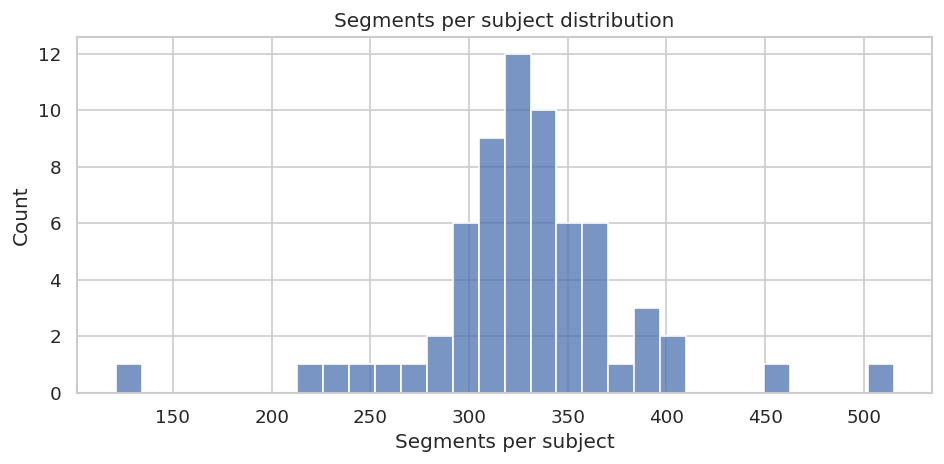

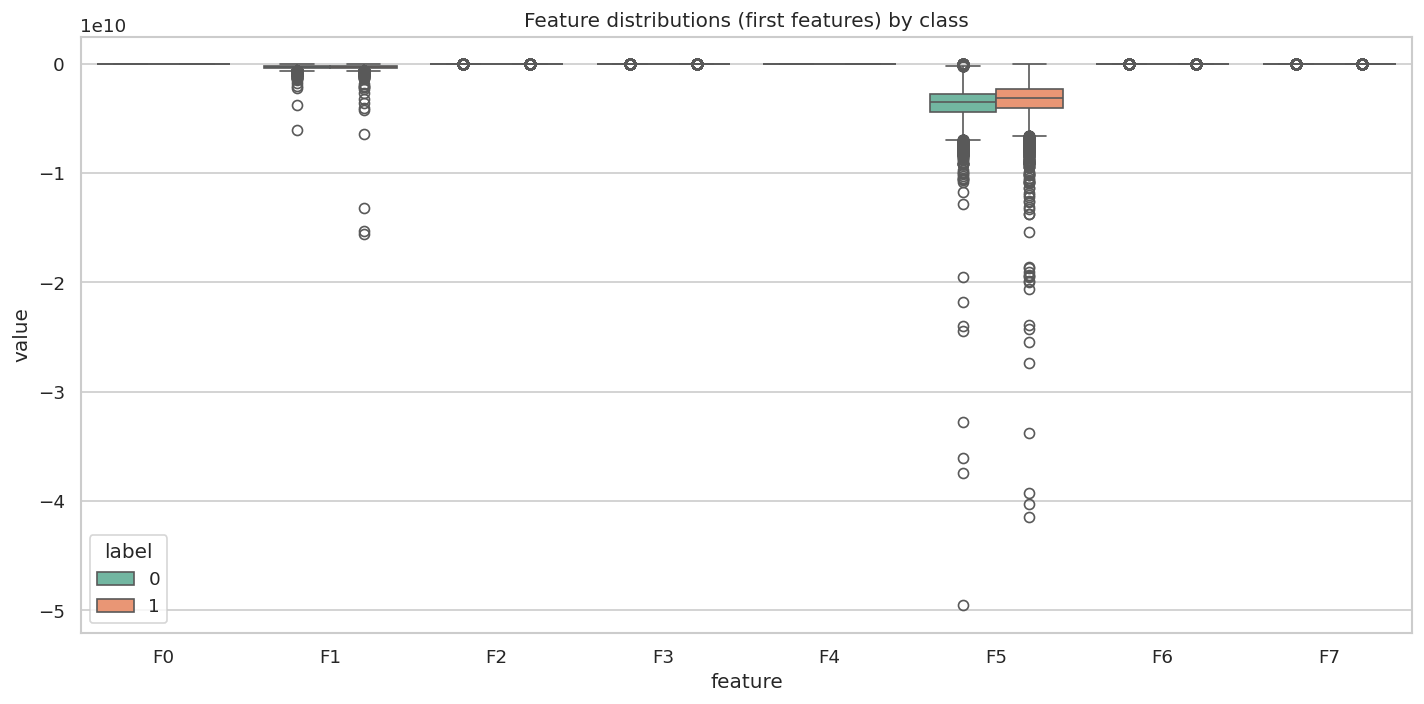

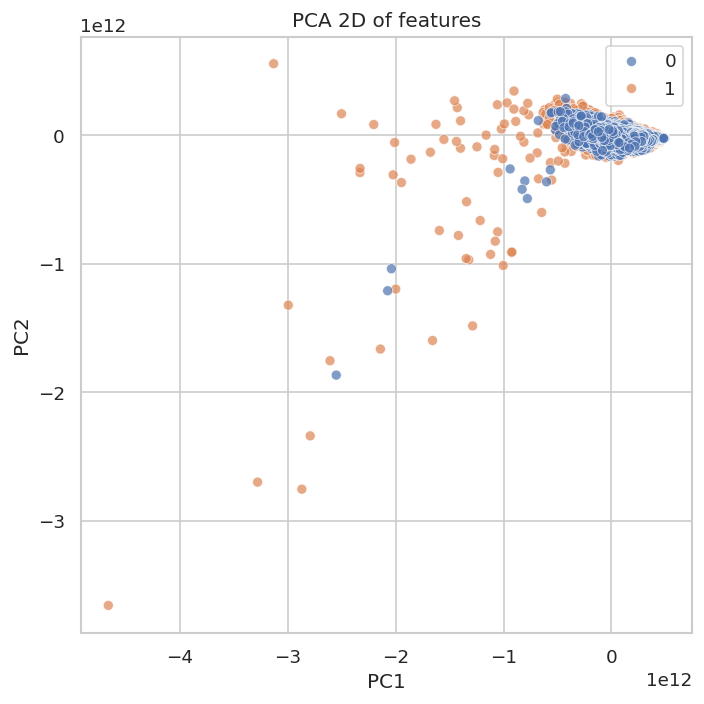

In [34]:
# Diagnostics: segments per subject, feature distributions and PCA
import seaborn as sns
from collections import Counter
from sklearn.decomposition import PCA
# segments per subject
seg_counts = Counter(all_subject_idx)
subj_df = pd.DataFrame.from_dict(seg_counts, orient='index', columns=['segments']).reset_index()
subj_df.columns = ['subject','segments']
plt.figure(figsize=(8,4))
sns.histplot(subj_df['segments'], bins=30, kde=False)
plt.xlabel('Segments per subject'); plt.title('Segments per subject distribution')
plt.tight_layout()
plt.savefig(save_dir / 'segments_per_subject.png', dpi=150)
plt.show()

# boxplot of first few features by class
num_features = X.shape[1]
num_show = min(8, num_features)
feat_idx = list(range(num_show))
feat_df = pd.DataFrame(X[:,feat_idx], columns=[f'F{i}' for i in feat_idx])
feat_df['label'] = y
melt = feat_df.melt(id_vars='label', var_name='feature', value_name='value')
plt.figure(figsize=(12,6))
sns.boxplot(x='feature', y='value', hue='label', data=melt, palette='Set2')
plt.title('Feature distributions (first features) by class')
plt.tight_layout()
plt.savefig(save_dir / 'feature_boxplots.png', dpi=150)
plt.show()

# PCA 2D scatter
pca = PCA(n_components=2)
X2 = pca.fit_transform(X)
plt.figure(figsize=(6,6))
sns.scatterplot(x=X2[:,0], y=X2[:,1], hue=y, palette='deep', alpha=0.7)
plt.title('PCA 2D of features'); plt.xlabel('PC1'); plt.ylabel('PC2')
plt.tight_layout()
plt.savefig(save_dir / 'pca_features.png', dpi=150)
plt.show()


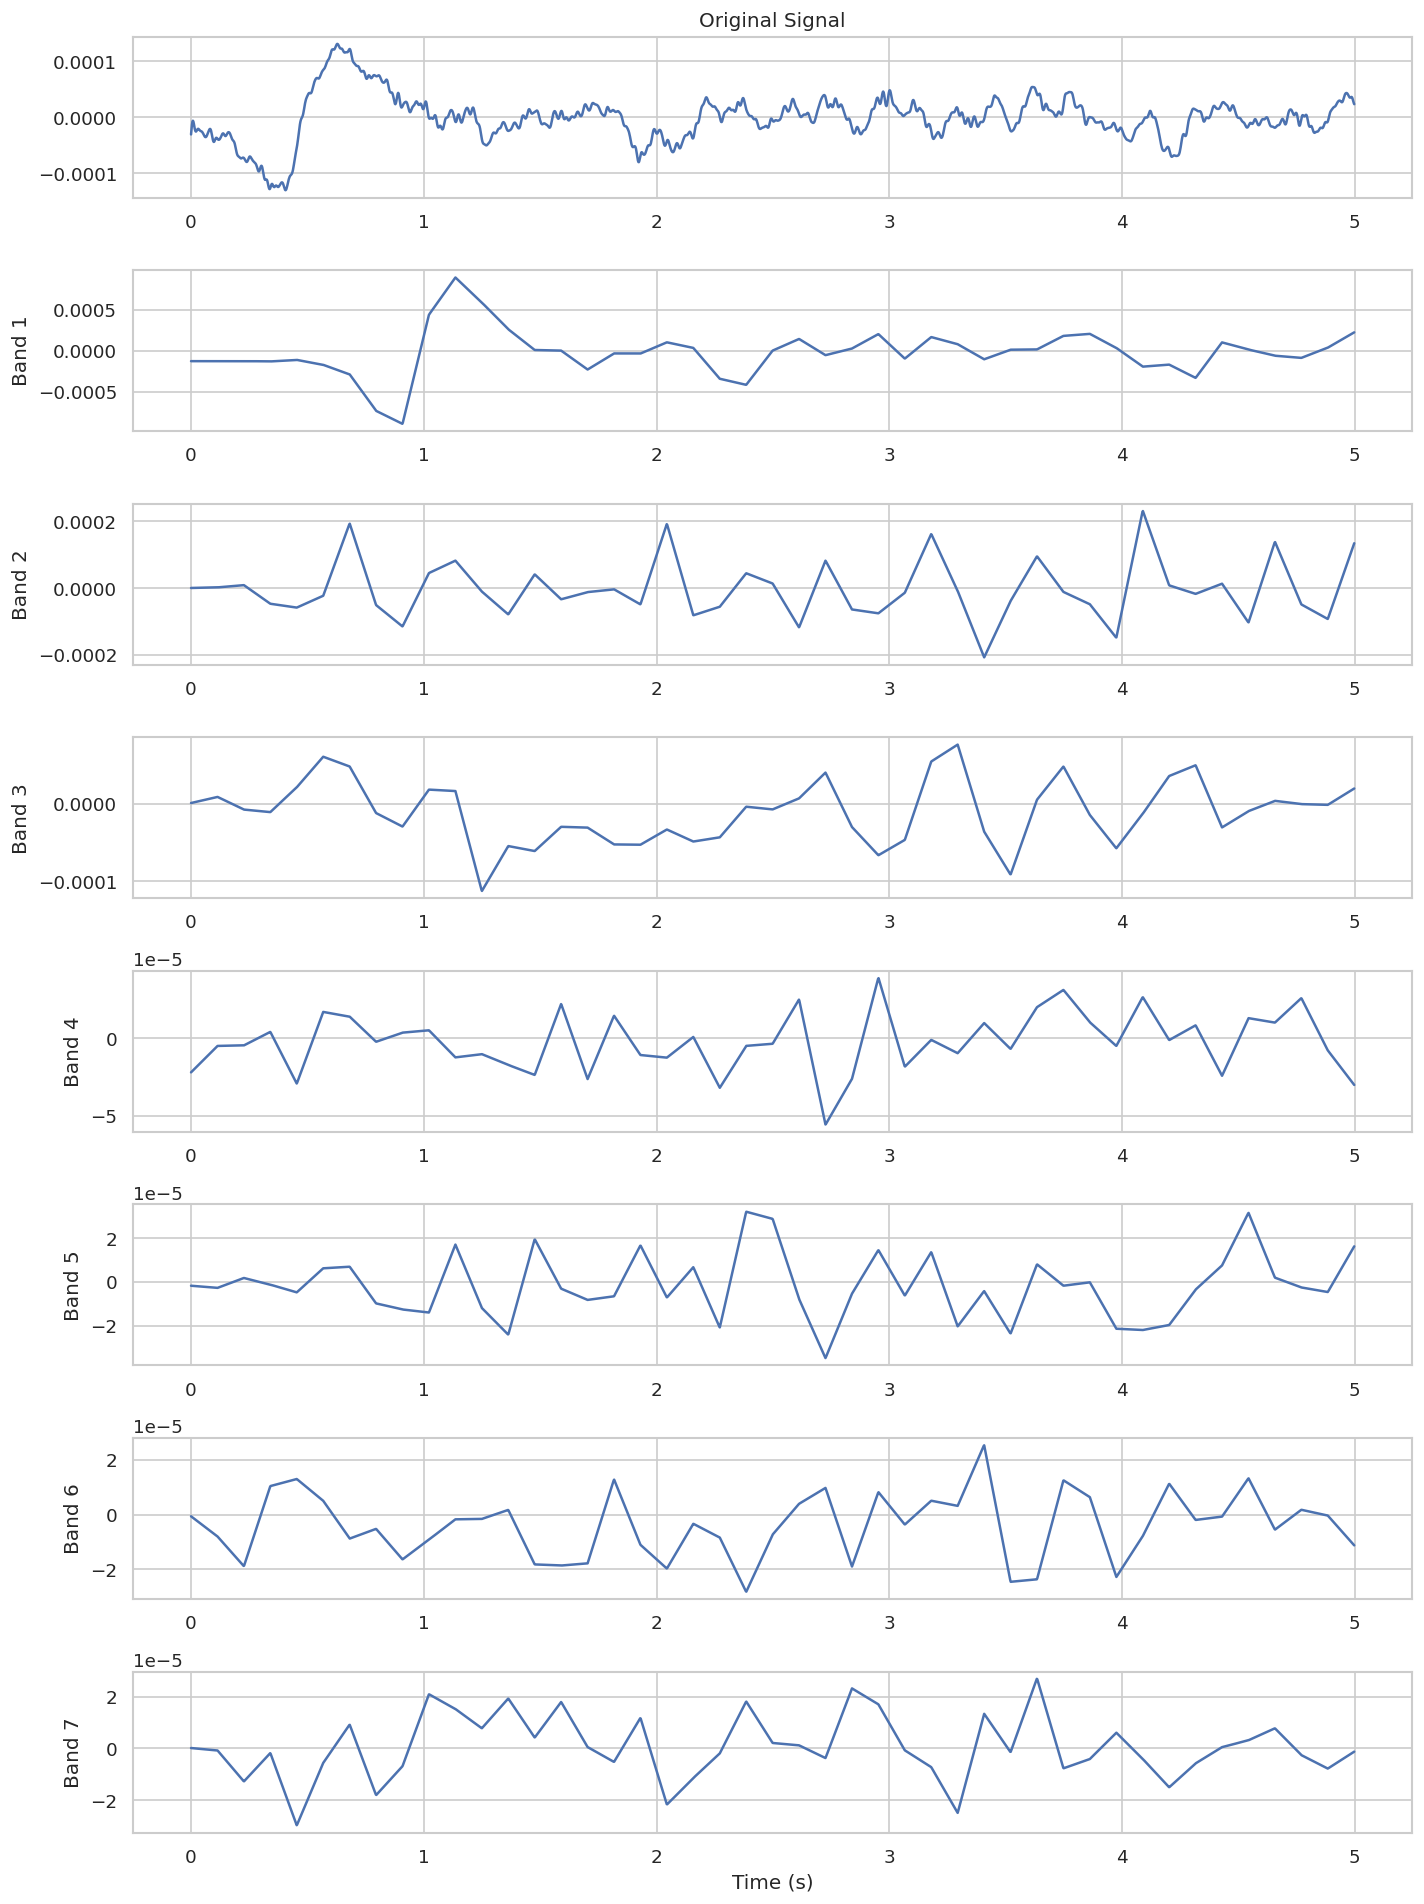

In [35]:
# Visualization: signal + TQWT subbands

# load one subject just for visualization
sub, filepath, label = manif[0]
raw = mne.io.read_raw_eeglab(filepath, preload=True, verbose='ERROR')

data = raw.get_data()
sig = data[0]  # first channel
sig = bandpass(sig)

segment = sig[:window_samples]

Q, R, J = estimate_tqwt_params(segment, fs_target)
bands = decompose_tqwt(segment, Q, R, J, fs_target)

def plot_decomposition(signal, subbands, fs=fs_target):
    t = np.arange(len(signal)) / fs
    n = len(subbands) + 1

    plt.figure(figsize=(12, 2*n))

    plt.subplot(n,1,1)
    plt.plot(t, signal)
    plt.title("Original Signal")

    for i, band in enumerate(subbands):
        plt.subplot(n,1,i+2)
        plt.plot(t, band)
        plt.ylabel(f"Band {i+1}")

    plt.xlabel("Time (s)")
    plt.tight_layout()
    plt.show()

plot_decomposition(segment, bands)


In [ ]:
# Cell 9: PyTorch Dataset
class EEGFeatureDataset(Dataset):
    def __init__(self, X, y, noise_std=1e-3):
        # store numpy and tensor versions; noise applied on the fly
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).long()
        self.noise_std = noise_std
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        x = self.X[idx]
        if self.noise_std and self.noise_std > 0:
            noise = torch.randn_like(x) * float(self.noise_std)
            x = x + noise
        return x, self.y[idx]

# standardize features (fit on all for now; better: fit on train in CV loop)
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_scaled = sc.fit_transform(X)
np.save(save_dir/"scaler_mean.npy", sc.mean_)
np.save(save_dir/"scaler_scale.npy", sc.scale_)

# dataset default will include small noise; during eval you may want noise_std=0
dataset = EEGFeatureDataset(X_scaled, y, noise_std=1e-3)


In [ ]:
# Cell 10: mixup augmentation
def mixup_data(x, y, alpha=0.8):
    '''Returns mixed inputs, pairs of targets, and lambda'''
    if alpha <= 0:
        return x, y, 1.0
    lam = np.random.beta(alpha, alpha)
    batch_size = x.size()[0]
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam


def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)


In [ ]:
# Cell 11: BiLSTM classifier
class BiLSTMClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, n_layers=2, dropout=0.5):
        super().__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.n_layers = n_layers
        # treat features as a sequence by splitting into "timesteps"
        # choose a timestep length: we can partition features into channels*subbands steps
        # We'll set timesteps = n_channels_expected and features_per_step = input_dim / timesteps
        self.timesteps = n_channels_expected
        assert input_dim % self.timesteps == 0, "input_dim must be divisible by timesteps"
        self.feat_per_step = input_dim // self.timesteps
        self.lstm = nn.LSTM(self.feat_per_step, hidden_dim, num_layers=n_layers,
                            batch_first=True, bidirectional=True, dropout=dropout)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim*2, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 1)
        )
    def forward(self, x):
        # x: batch x input_dim
        b = x.size(0)
        x = x.view(b, self.timesteps, self.feat_per_step)  # batch x timesteps x feat_per_step
        out, _ = self.lstm(x)  # batch x timesteps x (2*hidden_dim)
        # use last timestep
        out = out[:, -1, :]
        out = self.fc(out).squeeze(1)
        return out  # logits


In [ ]:
# Cell 12: training + 10-fold CV
from sklearn.utils.class_weight import compute_class_weight
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

INPUT_DIM = X_scaled.shape[1]
EPOCHS = 30
BATCH = 64
best_overall = {"auc":0.0, "model_path": None}

fold = 0
results = []

for train_idx, test_idx in skf.split(X_scaled, y):
    fold += 1
    print(f"\n===== Fold {fold} =====")
    X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # compute class weights for criterion
    cw = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
    weight_tensor = torch.tensor([cw[0], cw[1]]).float().to(device)  # not directly used in BCEWithLogits
    # use pos_weight in BCEWithLogits for binary imbalance: pos_weight = weight of positive class
    # derive pos_weight = cw[1] / cw[0]
    pos_weight = torch.tensor([cw[1]/cw[0]]).float().to(device)

    train_ds = EEGFeatureDataset(X_train, y_train, noise_std=1e-3)
    test_ds = EEGFeatureDataset(X_test, y_test, noise_std=0.0)
    train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, drop_last=True)
    test_loader = DataLoader(test_ds, batch_size=BATCH, shuffle=False)

    model = BiLSTMClassifier(INPUT_DIM, hidden_dim=128, n_layers=2, dropout=0.5).to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'max', patience=3, factor=0.5)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)  # handles imbalance

    best_auc = 0.0
    best_model_path = save_dir / f"best_fold{fold}.pt"
    early_stop_count = 0
    history = {'train_loss': [], 'val_auc': []}

    for epoch in range(1, EPOCHS+1):
        model.train()
        epoch_loss = 0.0
        all_preds = []
        all_targets = []
        for xb, yb in train_loader:
            xb = xb.to(device).float()
            yb = yb.to(device).float()
            # mixup (stronger)
            xb, ya, yb2, lam = mixup_data(xb, yb.long(), alpha=0.8)
            xb, ya, yb2 = xb.to(device).float(), ya.to(device).float(), yb2.to(device).float()
            optimizer.zero_grad()
            logits = model(xb)
            loss = mixup_criterion(criterion, logits, ya, yb2, lam)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()*xb.size(0)
            preds = torch.sigmoid(logits).detach().cpu().numpy()
            all_preds.extend(preds.tolist())
            all_targets.extend(ya.detach().cpu().numpy().tolist())
        epoch_loss /= len(train_loader.dataset)
        # eval
        model.eval()
        y_true = []
        y_score = []
        with torch.no_grad():
            for xb, yb in test_loader:
                xb = xb.to(device).float()
                logits = model(xb)
                probs = torch.sigmoid(logits).detach().cpu().numpy()
                y_score.extend(probs.tolist())
                y_true.extend(yb.numpy().tolist())
        # compute AUC
        try:
            auc = roc_auc_score(y_true, y_score)
        except:
            auc = 0.5
        print(f"Fold{fold} Epoch {epoch:02d} loss:{epoch_loss:.4f} val_auc:{auc:.4f}")
        scheduler.step(auc)
        # record history
        history['train_loss'].append(epoch_loss)
        history['val_auc'].append(auc)

        # checkpoint
        if auc > best_auc:
            torch.save(model.state_dict(), best_model_path)
            best_auc = auc
            early_stop_count = 0
        else:
            early_stop_count += 1
        if early_stop_count >= 6:
            print("Early stopping.")
            break

    # load best model for fold and evaluate detailed metrics
    model.load_state_dict(torch.load(best_model_path))
    model.eval()
    y_true = []
    y_score = []
    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(device).float()
            logits = model(xb)
            probs = torch.sigmoid(logits).detach().cpu().numpy()
            y_score.extend(probs.tolist())
            y_true.extend(yb.numpy().tolist())
    y_pred = [1 if p>=0.5 else 0 for p in y_score]
    auc = roc_auc_score(y_true, y_score)
    cm = confusion_matrix(y_true, y_pred)
    crep = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    results.append({"fold":fold, "auc":auc, "cm":cm, "report":crep, "model_path":str(best_model_path), 'history': history})
    print("Fold", fold, "AUC", auc, "CM\n", cm)
    # track best overall
    if auc > best_overall["auc"]:
        best_overall["auc"] = auc
        best_overall["model_path"] = str(best_model_path)

# save results summary
import pickle
with open(save_dir/"cv_results.pkl", "wb") as f:
    pickle.dump(results, f)
print("CV done. Best overall AUC:", best_overall["auc"], "model:", best_overall["model_path"])



===== Fold 1 =====
Fold1 Epoch 01 loss:0.5450 val_auc:0.8270
Fold1 Epoch 02 loss:0.4920 val_auc:0.8656
Fold1 Epoch 03 loss:0.4502 val_auc:0.9071
Fold1 Epoch 04 loss:0.4218 val_auc:0.9245
Fold1 Epoch 05 loss:0.4126 val_auc:0.9323
Fold1 Epoch 06 loss:0.3812 val_auc:0.9458
Fold1 Epoch 07 loss:0.3686 val_auc:0.9542
Fold1 Epoch 08 loss:0.3570 val_auc:0.9559
Fold1 Epoch 09 loss:0.3410 val_auc:0.9673
Fold1 Epoch 10 loss:0.3351 val_auc:0.9621
Fold1 Epoch 11 loss:0.3267 val_auc:0.9685
Fold1 Epoch 12 loss:0.3219 val_auc:0.9730
Fold1 Epoch 13 loss:0.3119 val_auc:0.9709
Fold1 Epoch 14 loss:0.2980 val_auc:0.9723
Fold1 Epoch 15 loss:0.3148 val_auc:0.9797
Fold1 Epoch 16 loss:0.3047 val_auc:0.9745
Fold1 Epoch 17 loss:0.2911 val_auc:0.9742
Fold1 Epoch 18 loss:0.2930 val_auc:0.9744
Fold1 Epoch 19 loss:0.2788 val_auc:0.9731
Fold1 Epoch 20 loss:0.2764 val_auc:0.9776
Fold1 Epoch 21 loss:0.2814 val_auc:0.9747
Fold1 Epoch 22 loss:0.2630 val_auc:0.9774
Fold1 Epoch 23 loss:0.2515 val_auc:0.9782
Fold1 Epoch 24

/tmp/ipykernel_7052/3569156154.py:96: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


Fold2 Epoch 01 loss:0.5346 val_auc:0.8361
Fold2 Epoch 02 loss:0.4711 val_auc:0.9016
Fold2 Epoch 03 loss:0.4488 val_auc:0.9077
Fold2 Epoch 04 loss:0.4386 val_auc:0.9231
Fold2 Epoch 05 loss:0.4156 val_auc:0.9390
Fold2 Epoch 06 loss:0.3907 val_auc:0.9412
Fold2 Epoch 07 loss:0.3737 val_auc:0.9525
Fold2 Epoch 08 loss:0.3670 val_auc:0.9550
Fold2 Epoch 09 loss:0.3596 val_auc:0.9583
Fold2 Epoch 10 loss:0.3389 val_auc:0.9636
Fold2 Epoch 11 loss:0.3448 val_auc:0.9670
Fold2 Epoch 12 loss:0.3334 val_auc:0.9655
Fold2 Epoch 13 loss:0.3161 val_auc:0.9702
Fold2 Epoch 14 loss:0.2956 val_auc:0.9731
Fold2 Epoch 15 loss:0.3155 val_auc:0.9714
Fold2 Epoch 16 loss:0.3046 val_auc:0.9719
Fold2 Epoch 17 loss:0.3028 val_auc:0.9767
Fold2 Epoch 18 loss:0.2949 val_auc:0.9790
Fold2 Epoch 19 loss:0.2931 val_auc:0.9772
Fold2 Epoch 20 loss:0.2840 val_auc:0.9768
Fold2 Epoch 21 loss:0.2740 val_auc:0.9812
Fold2 Epoch 22 loss:0.2977 val_auc:0.9785
Fold2 Epoch 23 loss:0.2841 val_auc:0.9778
Fold2 Epoch 24 loss:0.2737 val_auc

/tmp/ipykernel_7052/3569156154.py:96: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


Fold3 Epoch 01 loss:0.5383 val_auc:0.8406
Fold3 Epoch 02 loss:0.4736 val_auc:0.8877
Fold3 Epoch 03 loss:0.4421 val_auc:0.9116
Fold3 Epoch 04 loss:0.4207 val_auc:0.9262
Fold3 Epoch 05 loss:0.4041 val_auc:0.9396
Fold3 Epoch 06 loss:0.3912 val_auc:0.9374
Fold3 Epoch 07 loss:0.3819 val_auc:0.9470
Fold3 Epoch 08 loss:0.3602 val_auc:0.9538
Fold3 Epoch 09 loss:0.3599 val_auc:0.9544
Fold3 Epoch 10 loss:0.3447 val_auc:0.9609
Fold3 Epoch 11 loss:0.3326 val_auc:0.9613
Fold3 Epoch 12 loss:0.3425 val_auc:0.9620
Fold3 Epoch 13 loss:0.3210 val_auc:0.9606
Fold3 Epoch 14 loss:0.3129 val_auc:0.9721
Fold3 Epoch 15 loss:0.3208 val_auc:0.9717
Fold3 Epoch 16 loss:0.3050 val_auc:0.9725
Fold3 Epoch 17 loss:0.2918 val_auc:0.9742
Fold3 Epoch 18 loss:0.2971 val_auc:0.9749
Fold3 Epoch 19 loss:0.2932 val_auc:0.9742
Fold3 Epoch 20 loss:0.3001 val_auc:0.9776
Fold3 Epoch 21 loss:0.2902 val_auc:0.9766
Fold3 Epoch 22 loss:0.2724 val_auc:0.9785
Fold3 Epoch 23 loss:0.2817 val_auc:0.9758
Fold3 Epoch 24 loss:0.2699 val_auc

...

/tmp/ipykernel_7052/3569156154.py:96: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


Fold9 Epoch 01 loss:0.5441 val_auc:0.8433
Fold9 Epoch 02 loss:0.4787 val_auc:0.9045
Fold9 Epoch 03 loss:0.4504 val_auc:0.9135
Fold9 Epoch 04 loss:0.4192 val_auc:0.9309
Fold9 Epoch 05 loss:0.3928 val_auc:0.9483
Fold9 Epoch 06 loss:0.3873 val_auc:0.9568
Fold9 Epoch 07 loss:0.3813 val_auc:0.9580
Fold9 Epoch 08 loss:0.3627 val_auc:0.9604
Fold9 Epoch 09 loss:0.3651 val_auc:0.9584
Fold9 Epoch 10 loss:0.3468 val_auc:0.9687
Fold9 Epoch 11 loss:0.3449 val_auc:0.9687
Fold9 Epoch 12 loss:0.3256 val_auc:0.9670
Fold9 Epoch 13 loss:0.3266 val_auc:0.9761
Fold9 Epoch 14 loss:0.3114 val_auc:0.9748
Fold9 Epoch 15 loss:0.2976 val_auc:0.9790
Fold9 Epoch 16 loss:0.3005 val_auc:0.9769
Fold9 Epoch 17 loss:0.2979 val_auc:0.9759
Fold9 Epoch 18 loss:0.3102 val_auc:0.9779
Fold9 Epoch 19 loss:0.2884 val_auc:0.9770
Fold9 Epoch 20 loss:0.2796 val_auc:0.9786
Fold9 Epoch 21 loss:0.2820 val_auc:0.9783
Fold9 Epoch 22 loss:0.2671 val_auc:0.9834
Fold9 Epoch 23 loss:0.2665 val_auc:0.9806
Fold9 Epoch 24 loss:0.2668 val_auc

/tmp/ipykernel_7052/3569156154.py:96: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


Fold10 Epoch 01 loss:0.5444 val_auc:0.8425
Fold10 Epoch 02 loss:0.4838 val_auc:0.8885
Fold10 Epoch 03 loss:0.4493 val_auc:0.9080
Fold10 Epoch 04 loss:0.4327 val_auc:0.9234
Fold10 Epoch 05 loss:0.4140 val_auc:0.9352
Fold10 Epoch 06 loss:0.3996 val_auc:0.9479
Fold10 Epoch 07 loss:0.3863 val_auc:0.9500
Fold10 Epoch 08 loss:0.3741 val_auc:0.9551
Fold10 Epoch 09 loss:0.3503 val_auc:0.9625
Fold10 Epoch 10 loss:0.3365 val_auc:0.9653
Fold10 Epoch 11 loss:0.3457 val_auc:0.9676
Fold10 Epoch 12 loss:0.3209 val_auc:0.9697
Fold10 Epoch 13 loss:0.3090 val_auc:0.9691
Fold10 Epoch 14 loss:0.3296 val_auc:0.9743
Fold10 Epoch 15 loss:0.2951 val_auc:0.9791
Fold10 Epoch 16 loss:0.2910 val_auc:0.9755
Fold10 Epoch 17 loss:0.2899 val_auc:0.9758
Fold10 Epoch 18 loss:0.2889 val_auc:0.9760
Fold10 Epoch 19 loss:0.2924 val_auc:0.9749
Fold10 Epoch 20 loss:0.2785 val_auc:0.9811
Fold10 Epoch 21 loss:0.2921 val_auc:0.9809
Fold10 Epoch 22 loss:0.2607 val_auc:0.9803
Fold10 Epoch 23 loss:0.2620 val_auc:0.9809
Fold10 Epoc

/tmp/ipykernel_7052/3569156154.py:96: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


/tmp/ipykernel_7052/325129476.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(range(1,len(aucs)+1)), y=aucs, palette='viridis')


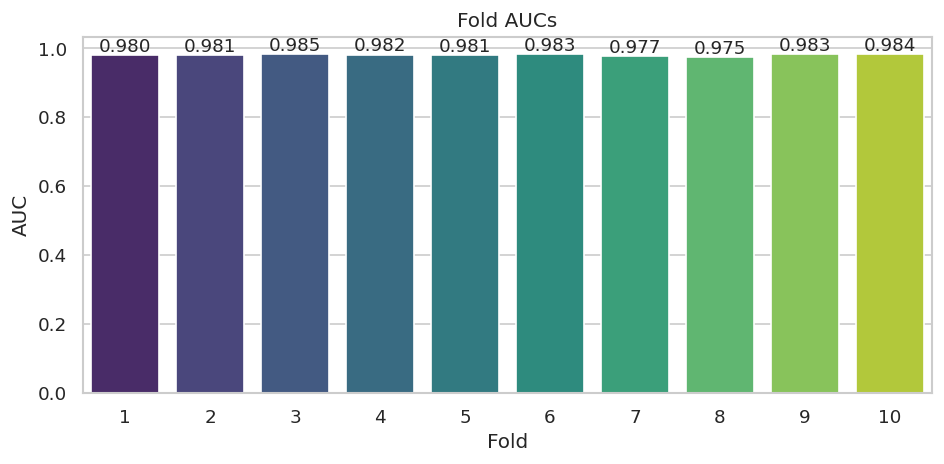

Best fold: 3 AUC: 0.9845433888341323
Classification report (best fold):
              precision    recall  f1-score     support
0              0.942887  0.933196  0.938017   973.00000
1              0.944962  0.953032  0.948980  1171.00000
accuracy       0.944030  0.944030  0.944030     0.94403
macro avg      0.943924  0.943114  0.943498  2144.00000
weighted avg   0.944020  0.944030  0.944004  2144.00000


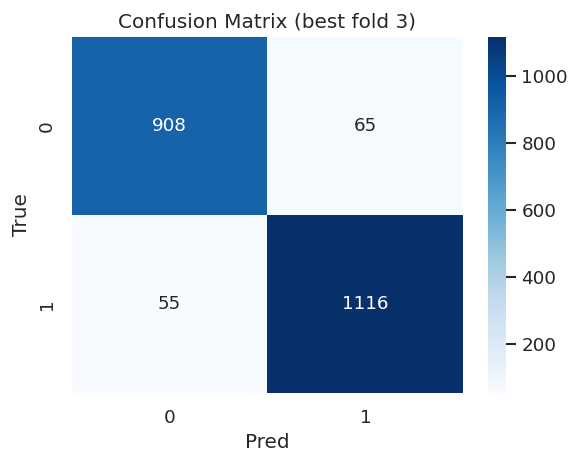

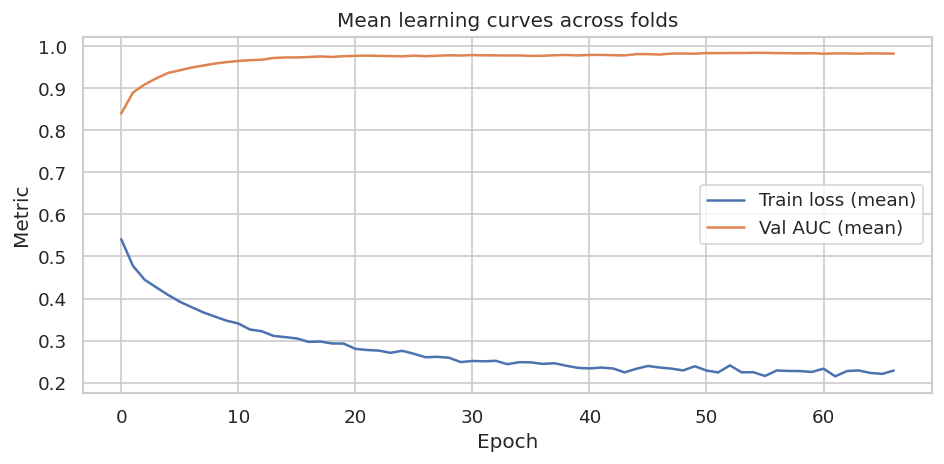

In [40]:
# Cell 13: improved plotting of fold metrics
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
with open(save_dir/"cv_results.pkl","rb") as f:
    res = pickle.load(f)

# aggregate AUCs
aucs = [r['auc'] for r in res]
plt.figure(figsize=(8,4))
sns.barplot(x=list(range(1,len(aucs)+1)), y=aucs, palette='viridis')
plt.xlabel("Fold"); plt.ylabel("AUC"); plt.title("Fold AUCs")
for i,v in enumerate(aucs):
    plt.text(i, v+0.01, f"{v:.3f}", ha='center')
plt.tight_layout()
plt.savefig(save_dir/"fold_aucs.png", dpi=150)
plt.show()

# show confusion matrix of best fold (heatmap)
best = max(res, key=lambda x: x['auc'])
print("Best fold:", best['fold'], "AUC:", best['auc'])
print("Classification report (best fold):")
print(pd.DataFrame(best['report']).T)
cm = best['cm']
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Pred"); plt.ylabel("True"); plt.title(f"Confusion Matrix (best fold {best['fold']})")
plt.tight_layout()
plt.savefig(save_dir/"best_confusion.png", dpi=150)
plt.show()

# mean learning curves across folds if histories exist
histories = [r.get('history') for r in res if r.get('history') is not None]
if histories:
    import numpy as _np
    max_epochs = max(len(h['train_loss']) for h in histories)
    all_train = _np.array([h['train_loss'] + [ _np.nan ]*(max_epochs - len(h['train_loss'])) for h in histories])
    all_val = _np.array([h['val_auc'] + [ _np.nan ]*(max_epochs - len(h['val_auc'])) for h in histories])
    mean_train = _np.nanmean(all_train, axis=0)
    mean_val = _np.nanmean(all_val, axis=0)
    plt.figure(figsize=(8,4))
    plt.plot(mean_train, label='Train loss (mean)')
    plt.plot(mean_val, label='Val AUC (mean)')
    plt.xlabel('Epoch'); plt.ylabel('Metric'); plt.legend(); plt.title('Mean learning curves across folds')
    plt.tight_layout()
    plt.savefig(save_dir/"learning_curves_mean.png", dpi=150)
    plt.show()


In [41]:
# Cell 14: final save and example report
print("Best model saved at:", best_overall["model_path"])
# load and show sample predictions with that model (if desired)
final_model = BiLSTMClassifier(INPUT_DIM).to(device)
final_model.load_state_dict(torch.load(best_overall["model_path"]))
final_model.eval()
# Optionally export to ONNX if requested (skipped per choice)


Best model saved at: results_bilstm/best_fold3.pt


/tmp/ipykernel_7052/2083957647.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  final_model.load_state_dict(torch.load(best_overall["model_path"]))


BiLSTMClassifier(
  (lstm): LSTM(28, 256, num_layers=2, batch_first=True, dropout=0.4, bidirectional=True)
  (fc): Sequential(
    (0): Linear(in_features=512, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=128, out_features=1, bias=True)
  )
)

Best fold: 3 | AUC: 0.985


/tmp/ipykernel_7052/1300604127.py:28: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


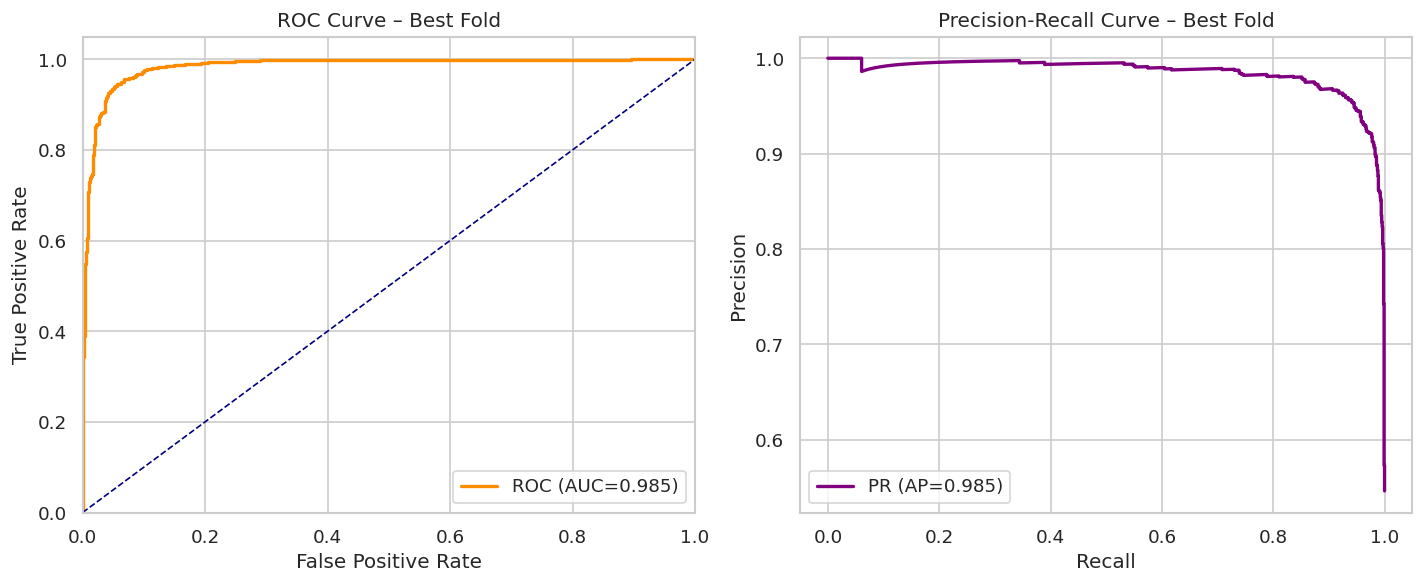

In [42]:
# Plot ROC and Precision-Recall curve for best fold
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

# Load results
with open(save_dir / "cv_results.pkl", "rb") as f:
    res = pickle.load(f)

best = max(res, key=lambda x: x['auc'])
print(f"Best fold: {best['fold']} | AUC: {best['auc']:.3f}")

# Extract test data for best fold
from sklearn.model_selection import StratifiedKFold
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
fold = 0
for train_idx, test_idx in skf.split(X_scaled, y):
    fold += 1
    if fold == best['fold']:
        X_test = X_scaled[test_idx]
        y_test = y[test_idx]
        break

# Reload best model
best_model_path = best['model_path']
model = BiLSTMClassifier(X_scaled.shape[1]).to(device)
model.load_state_dict(torch.load(best_model_path))
model.eval()

with torch.no_grad():
    xb = torch.from_numpy(X_test).to(device).float()
    preds = torch.sigmoid(model(xb)).cpu().numpy().flatten()

fpr, tpr, _ = roc_curve(y_test, preds)
roc_auc = auc(fpr, tpr)
precision, recall, _ = precision_recall_curve(y_test, preds)
ap = average_precision_score(y_test, preds)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC={roc_auc:.3f})')
plt.plot([0,1], [0,1], color='navy', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – Best Fold')
plt.legend(loc="lower right")
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(recall, precision, color='purple', lw=2, label=f'PR (AP={ap:.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve – Best Fold')
plt.legend(loc='lower left')
plt.grid(True)

plt.tight_layout()
plt.savefig(save_dir / "roc_pr_best_fold.png", dpi=150)
plt.show()


Found histories for 10 folds
Fold 1: min_train_epoch=23, max_val_epoch=15, max_val=0.9797, final_val=0.9786, val_drop=0.0011, flag=True
Fold 2: min_train_epoch=31, max_val_epoch=21, max_val=0.9812, final_val=0.9796, val_drop=0.0016, flag=True
Fold 3: min_train_epoch=44, max_val_epoch=55, max_val=0.9845, final_val=0.9825, val_drop=0.0020, flag=True
Fold 4: min_train_epoch=43, max_val_epoch=35, max_val=0.9818, final_val=0.9792, val_drop=0.0025, flag=True
Fold 5: min_train_epoch=41, max_val_epoch=29, max_val=0.9813, final_val=0.9792, val_drop=0.0021, flag=True
Fold 6: min_train_epoch=49, max_val_epoch=38, max_val=0.9834, final_val=0.9814, val_drop=0.0020, flag=True
Fold 7: min_train_epoch=44, max_val_epoch=32, max_val=0.9768, final_val=0.9706, val_drop=0.0062, flag=True
Fold 8: min_train_epoch=38, max_val_epoch=26, max_val=0.9748, final_val=0.9713, val_drop=0.0035, flag=True
Fold 9: min_train_epoch=34, max_val_epoch=22, max_val=0.9834, final_val=0.9818, val_drop=0.0016, flag=True
Fold 10:

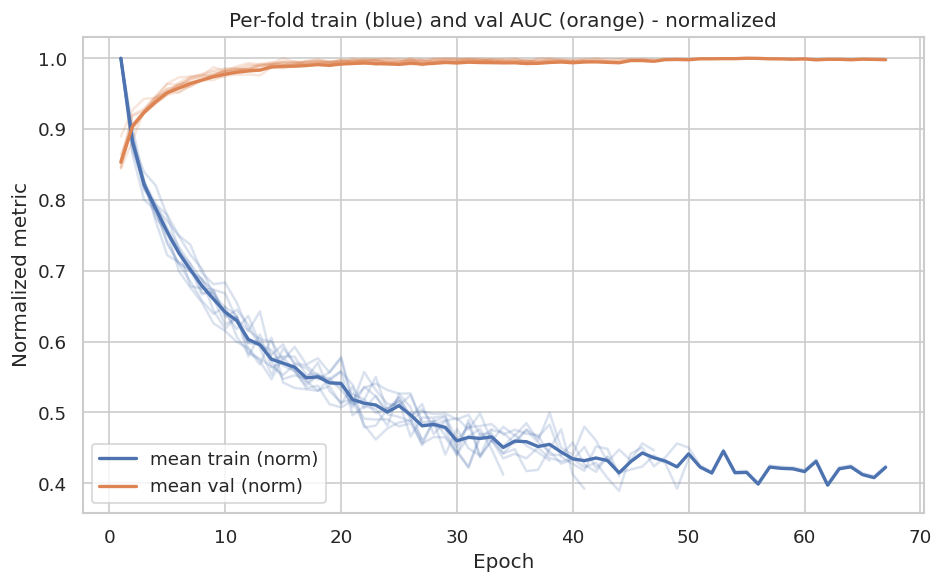

Conclusion: Likely overfitting in 10/10 folds (majority).


In [43]:
# Overfitting check: per-fold summary and aggregated decision
import numpy as np
import matplotlib.pyplot as plt

histories = [r.get('history') for r in results if r.get('history') is not None]
if not histories:
    print('No training histories available to analyze overfitting.')
else:
    print(f'Found histories for {len(histories)} folds')
    fold_flags = []
    plt.figure(figsize=(8,5))
    for i,h in enumerate(histories):
        tr = np.array(h['train_loss'], dtype=np.float64)
        va = np.array(h['val_auc'], dtype=np.float64)
        epochs = np.arange(1, len(tr)+1)
        # per-fold plot (thin)
        plt.plot(epochs, tr/np.nanmax(tr), color='C0', alpha=0.2)
        plt.plot(epochs, va/np.nanmax(va), color='C1', alpha=0.2)
        # metrics
        min_tr_epoch = int(np.nanargmin(tr))+1
        max_va_epoch = int(np.nanargmax(va))+1
        final_tr = float(tr[-1])
        final_va = float(va[-1])
        max_va = float(np.nanmax(va))
        # heuristics for overfit: validation peak earlier than end and validation drops from peak
        va_drop = max_va - final_va
        gap_epoch = min_tr_epoch - max_va_epoch
        flag = False
        reasons = []
        if va_drop > 0.02:
            flag = True
            reasons.append(f"val drop {va_drop:.3f}")
        if max_va_epoch < len(va) - 5:
            flag = True
            reasons.append(f"val peak early (epoch {max_va_epoch})")
        fold_flags.append((i+1, flag, reasons, {'min_train_epoch':min_tr_epoch,'max_val_epoch':max_va_epoch,'max_val':max_va,'final_val':final_va}))
        print(f"Fold {i+1}: min_train_epoch={min_tr_epoch}, max_val_epoch={max_va_epoch}, max_val={max_va:.4f}, final_val={final_va:.4f}, val_drop={va_drop:.4f}, flag={flag}")
    # mean curves
    max_epochs = max(len(h['train_loss']) for h in histories)
    all_train = np.array([h['train_loss'] + [np.nan]*(max_epochs - len(h['train_loss'])) for h in histories])
    all_val = np.array([h['val_auc'] + [np.nan]*(max_epochs - len(h['val_auc'])) for h in histories])
    mean_train = np.nanmean(all_train, axis=0)
    mean_val = np.nanmean(all_val, axis=0)
    epochs = np.arange(1, len(mean_train)+1)
    plt.plot(epochs, mean_train/np.nanmax(mean_train), label='mean train (norm)', color='C0', lw=2)
    plt.plot(epochs, mean_val/np.nanmax(mean_val), label='mean val (norm)', color='C1', lw=2)
    plt.xlabel('Epoch'); plt.ylabel('Normalized metric'); plt.legend(); plt.title('Per-fold train (blue) and val AUC (orange) - normalized')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # aggregate decision
    flags = [f[1] for f in fold_flags]
    n_flag = sum(flags)
    if n_flag / len(flags) > 0.5:
        print(f"Conclusion: Likely overfitting in {n_flag}/{len(flags)} folds (majority).")
    elif n_flag > 0:
        print(f"Conclusion: Some folds ({n_flag}/{len(flags)}) show signs of overfitting.")
    else:
        print('Conclusion: No strong evidence of overfitting across folds.')
